**Week 1: Superstore Sales – Data Cleaning & Exploratory Analysis**

1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import zscore

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

2. Load the Dataset

In [2]:
df = pd.read_csv('/content/drive/MyDrive/EDA-Skill/samplesuperstore.csv')

print("Dataset loaded successfully")

df.head()

Dataset loaded successfully


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


3. Inspect Dataset Dimensions

In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Number of Rows: 10194
Number of Columns: 21

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


4. Display First and Last Records

In [4]:
print("First 5 Records:")
display(df.head())

print("Last 5 Records:")
display(df.tail())

First 5 Records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


Last 5 Records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10189,10190,US-2026-143259,12/30/2026,1/3/2027,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,New York,10009,East,OFF-BI-10003684,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910
10190,10191,US-2026-115427,12/30/2026,1/3/2027,Standard Class,EB-13975,Erica Bern,Corporate,United States,Fairfield,California,94533,West,OFF-BI-10004632,Office Supplies,Binders,GBC Binding covers,20.720,2,0.2,6.4750
10191,10192,US-2026-156720,12/30/2026,1/3/2027,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Loveland,Colorado,80538,West,OFF-FA-10003472,Office Supplies,Fasteners,Bagged Rubber Bands,3.024,3,0.2,-0.6048
10192,10193,US-2026-143259,12/30/2026,1/3/2027,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,New York,10009,East,TEC-PH-10004774,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279
10193,10194,CA-2026-143500,12/30/2026,1/3/2027,Standard Class,HO-15230,Harry Olson,Consumer,Canada,Charlottetown,Prince Edward Island,C0A,East,OFF-BI-10004040,Office Supplies,Binders,Wilson Jones Impact Binders,3.024,3,0.2,-0.6048


5. Dataset Information

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non-null  object 
 12  Region          10194 non-null  object 
 13  Product ID      10194 non-null  object 
 14  Category        10194 non-null  object 
 15  Sub-Category    10194 non-null  object 
 16  Product Name    10194 non-null  object 
 17  Sales           10194 non-null 

6. Statistical Summary

In [6]:
df.describe()

,Row ID,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,228.225854,3.791838,0.155385,28.673417
std,2942.898656,619.906839,2.228317,0.206249,232.465115
min,1.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,209.500000,5.000000,0.200000,29.297925
max,10194.000000,22638.480000,14.000000,0.800000,8399.976000


In [7]:
df.describe(include='all')

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194,10194,10194,10194,10194,10194,10194,10194,10194,10194,10194,10194,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
unique,NaN,5111,1242,1338,4,804,800,3,2,542,59,654,4,1862,3,17,1849,NaN,NaN,NaN,NaN
top,NaN,US-2026-100111,9/5/2025,12/16/2024,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,10035,West,FUR-FU-10004270,Office Supplies,Binders,Staples,NaN,NaN,NaN,NaN
freq,NaN,14,38,38,6120,41,41,5281,9994,915,2001,263,3253,20,6128,1548,50,NaN,NaN,NaN,NaN
mean,5097.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,228.225854,3.791838,0.155385,28.673417
std,2942.898656,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,619.906839,2.228317,0.206249,232.465115
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,209.500000,5.000000,0.200000,29.297925


7. Missing Value Analysis

In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


In [9]:
missing_data = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': df.isnull().mean() * 100
})

display(missing_data)

,Missing Count,Missing Percentage
Row ID,0,0.0
Order ID,0,0.0
Order Date,0,0.0
Ship Date,0,0.0
Ship Mode,0,0.0
Customer ID,0,0.0
Customer Name,0,0.0
Segment,0,0.0
Country/Region,0,0.0
City,0,0.0


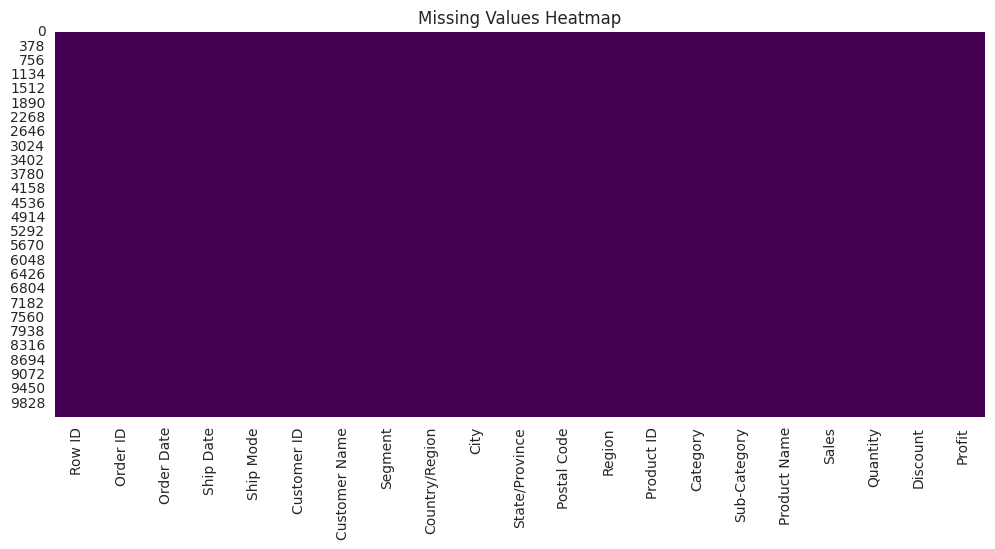

In [10]:
plt.figure(figsize=(12, 5))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values Heatmap")
plt.show()

8. Handle Missing Values

In [11]:
# Create a copy of the original dataset
df_clean = df.copy()

# Replace '?' with NaN
df_clean.replace('?', np.nan, inplace=True)

# Fill numerical missing values using median
numeric_cols = df_clean.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill categorical missing values using mode
categorical_cols = df_clean.select_dtypes(include='object').columns

for col in categorical_cols:
    if df_clean[col].isnull().any():
        mode_value = df_clean[col].mode()

        if not mode_value.empty:
            df_clean[col] = df_clean[col].fillna(mode_value[0])

print("Missing values handled.")

print(df_clean.isnull().sum())

Missing values handled.
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


9. Duplicate Record Analysis

In [12]:
print("Number of Duplicate Records:",
      df_clean.duplicated().sum())

Number of Duplicate Records: 0


In [13]:
df_clean.drop_duplicates(inplace=True)

print("Dataset Shape After Removing Duplicates:")
print(df_clean.shape)

Dataset Shape After Removing Duplicates:
(10194, 21)


10. Convert Date Columns

In [14]:
df_clean['Order Date'] = pd.to_datetime(
    df_clean['Order Date'],
    errors='coerce'
)

df_clean['Ship Date'] = pd.to_datetime(
    df_clean['Ship Date'],
    errors='coerce'
)

print(df_clean[['Order Date', 'Ship Date']].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


11. Standardize Categorical Columns

In [15]:
categorical_columns = [
    'Category',
    'Sub-Category',
    'Segment',
    'Ship Mode',
    'City',
    'Region',
    'State'
]

for col in categorical_columns:
    if col in df_clean.columns:
        df_clean[col] = (
            df_clean[col]
            .astype('string')
            .str.strip()
            .str.replace(r'\s+', ' ', regex=True)
            .str.title()
        )

display(df_clean.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


12. Numerical Summary Statistics

In [16]:
numerical_columns = [
    'Sales',
    'Quantity',
    'Profit',
    'Discount'
]

available_columns = [
    col for col in numerical_columns
    if col in df_clean.columns
]

display(df_clean[available_columns].describe())

,Sales,Quantity,Profit,Discount
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,3.791838,28.673417,0.155385
std,619.906839,2.228317,232.465115,0.206249
min,0.444000,1.000000,-6599.978000,0.000000
25%,17.220000,2.000000,1.760800,0.000000
50%,53.910000,3.000000,8.690000,0.200000
75%,209.500000,5.000000,29.297925,0.200000
max,22638.480000,14.000000,8399.976000,0.800000


In [17]:
summary = pd.DataFrame({
    'Mean': df_clean[available_columns].mean(),
    'Median': df_clean[available_columns].median(),
    'Standard Deviation': df_clean[available_columns].std(),
    'Minimum': df_clean[available_columns].min(),
    'Maximum': df_clean[available_columns].max()
})

display(summary)

,Mean,Median,Standard Deviation,Minimum,Maximum
Sales,228.225854,53.91,619.906839,0.444,22638.480
Quantity,3.791838,3.00,2.228317,1.000,14.000
Profit,28.673417,8.69,232.465115,-6599.978,8399.976
Discount,0.155385,0.20,0.206249,0.000,0.800


13. Outlier Detection Using IQR

In [18]:
for col in available_columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print("\nColumn:", col)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Column: Sales
Lower Bound: -271.20000000000005
Upper Bound: 497.92
Number of Outliers: 1183

Column: Quantity
Lower Bound: -2.5
Upper Bound: 9.5
Number of Outliers: 175

Column: Profit
Lower Bound: -39.544887499999994
Upper Bound: 70.6036125
Number of Outliers: 1913

Column: Discount
Lower Bound: -0.30000000000000004
Upper Bound: 0.5
Number of Outliers: 874


14. Visualize Outliers Using Boxplots

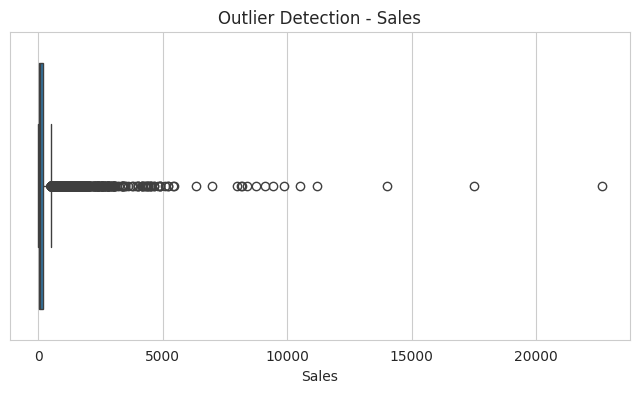

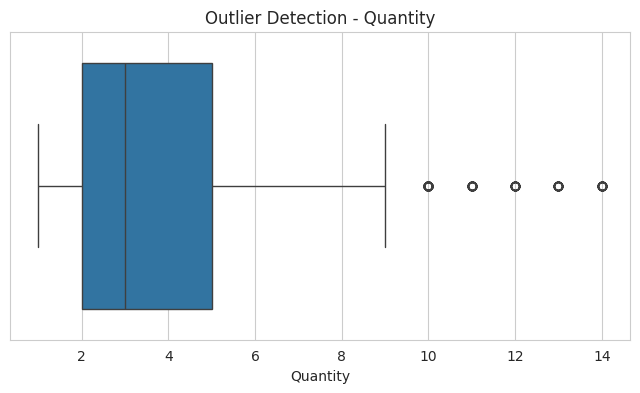

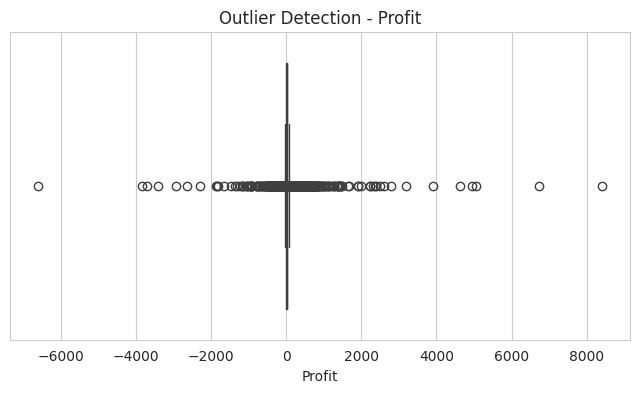

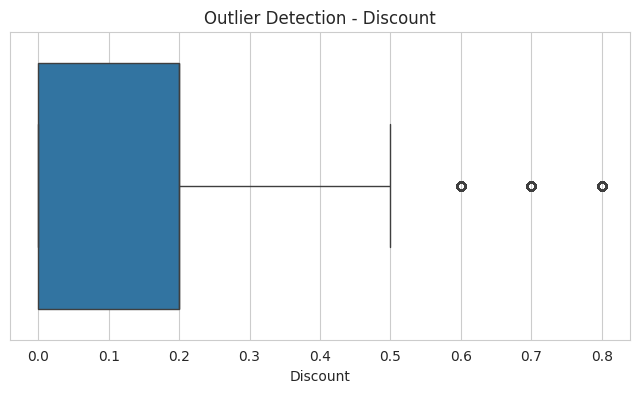

In [19]:
for col in available_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df_clean[col])

    plt.title("Outlier Detection - " + col)
    plt.xlabel(col)

    plt.show()

15. Outlier Detection Using Z-Score

In [20]:
for col in available_columns:

    z_scores = np.abs(zscore(df_clean[col].dropna()))

    outlier_count = np.sum(z_scores > 3)

    print("\nColumn:", col)
    print("Number of Z-Score Outliers:", outlier_count)


Column: Sales
Number of Z-Score Outliers: 128

Column: Quantity
Number of Z-Score Outliers: 114

Column: Profit
Number of Z-Score Outliers: 109

Column: Discount
Number of Z-Score Outliers: 301


16. Final Dataset Validation

In [21]:
print("Original Dataset Shape:", df.shape)

print("Cleaned Dataset Shape:", df_clean.shape)

print("\nRemaining Missing Values:")
print(df_clean.isnull().sum())

print("\nRemaining Duplicate Records:")
print(df_clean.duplicated().sum())

print("\nFinal Dataset Information:")
df_clean.info()

Original Dataset Shape: (10194, 21)
Cleaned Dataset Shape: (10194, 21)

Remaining Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

Remaining Duplicate Records:
0

Final Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  dat

17. Export Cleaned Dataset

In [22]:
df_clean.to_csv(
    'Superstore_Cleaned.csv',
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


18. Final Conclusion

In [23]:
print("""
CONCLUSION:

1. The Superstore dataset was successfully loaded and inspected.
2. Missing values were identified and handled.
3. Duplicate records were detected and removed.
4. Order Date and Ship Date were converted into datetime format.
5. Categorical attributes were standardized.
6. Numerical summary statistics were calculated.
7. Outliers were identified using IQR and Z-Score methods.
8. The cleaned dataset was exported for further analysis.

The prepared dataset can be used for Week 2:
Retail Sales Visualization and Business Insights.
""")


CONCLUSION:

1. The Superstore dataset was successfully loaded and inspected.
2. Missing values were identified and handled.
3. Duplicate records were detected and removed.
4. Order Date and Ship Date were converted into datetime format.
5. Categorical attributes were standardized.
6. Numerical summary statistics were calculated.
7. Outliers were identified using IQR and Z-Score methods.
8. The cleaned dataset was exported for further analysis.

The prepared dataset can be used for Week 2:
Retail Sales Visualization and Business Insights.

